In [15]:

import numpy as np
import matplotlib.pyplot as plt

K = 3

n = 10000 

# class 1
mu1 =  [
    [1, 0],
    [1, 5],
    [1, 10]
]

#Class 2
mu2 = [
    [9, 0],
    [9, 5],
    [9, 10]
]

# Mixture weights
pi1 = [0.3, 0.4, 0.3]
pi2 = [0.2, 0.5, 0.3]



In [16]:

from math import log,sqrt,cos,sin,pi

seed=42
# Linear Congruential Generator (LCG)
def random_number():
    global seed
    seed=(1664525*seed+1013904223)%(2**32)
    return seed/(2**32)
    
# Box-Muller Transform
def box_muller():
    u1=random_number()
    u2=random_number()
    while u1==0:
        u1=random_number()
    z1=sqrt(-2*log(u1))*cos(2*pi*u2)
    z2=sqrt(-2*log(u1))*sin(2*pi*u2)
    return np.array([z1,z2])


In [17]:

# Spherical covariance
C_spherical = np.array([
    [4, 0],
    [0, 4]
])

# Diagonal covariance
C_diagonal = np.array([
    [4, 0],
    [0, 1]
])

# Full covariance
C_full = np.array([
    [4, 2],
    [2, 3]
])


In [18]:
# Generate a uniform random number between 0 and 1

def select_component(weights):
    r = random_number()

    if r < weights[0]:
        return 0
    elif weights[0] < r < weights[0] + weights[1]:
        return 1
    else:
        return 2






In [19]:

def covariance_transform(C):
    a = np.sqrt(C[0, 0])
    b = C[1, 0] / a
    c = np.sqrt(C[1, 1] - b * b)

    return np.array([
        [a, 0],
        [b, c]
    ])


def generate_data(means, weights, C, n):
    data = []
    components = []

    A = covariance_transform(C)

    for i in range(n):
        k = select_component(weights)

        z = box_muller()

        x=np.array(means[k])+np.dot(A,z)
        data.append(x)
        components.append(k)

    return np.array(data), np.array(components)


# Generate spherical covariance data
X1, labels1 = generate_data(mu1, pi1, C_spherical, n)
X2, labels2 = generate_data(mu2, pi2, C_spherical, n)

print("Class 1 Data Shape:", X1.shape)
print("Class 2 Data Shape:", X2.shape)


Class 1 Data Shape: (10000, 2)
Class 2 Data Shape: (10000, 2)


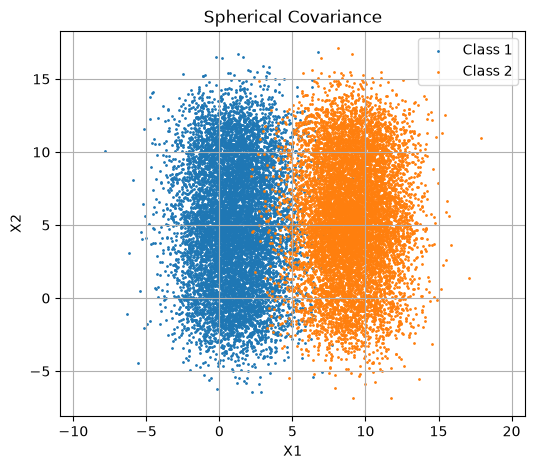

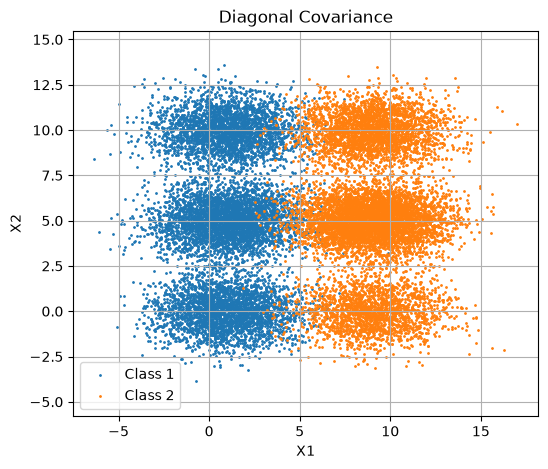

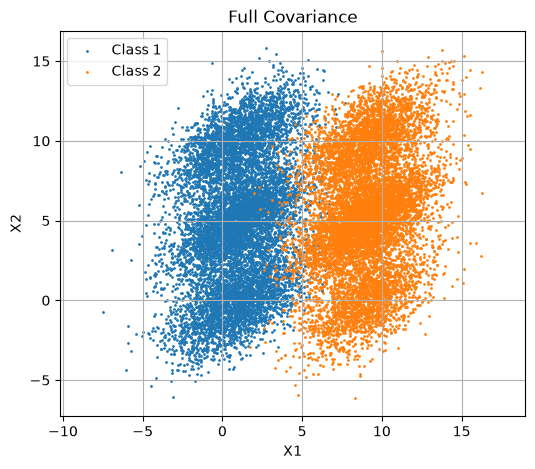

In [20]:

covariances = [
    ("Spherical Covariance", C_spherical),
    ("Diagonal Covariance", C_diagonal),
    ("Full Covariance", C_full)
]

for title, C in covariances:

    X1, labels1 = generate_data(mu1, pi1, C, n)
    X2, labels2 = generate_data(mu2, pi2, C, n)

    plt.figure(figsize=(6,5))

    plt.scatter(X1[:, 0], X1[:, 1],
                s=1, 
                label="Class 1")

    plt.scatter(X2[:, 0], X2[:, 1],
                s=1, 
                label="Class 2")

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.legend()
    plt.grid(True)
    plt.axis("equal")
    plt.show()


In [21]:
def split_data(X):
    X = X.copy()
    n = len(X)

    for i in range(n - 1, 0, -1):
        j = int(random_number() * (i + 1))
        X[i], X[j] = X[j].copy(), X[i].copy()

    n_train = int(0.8 * n)

    train = X[:n_train]
    test = X[n_train:]

    return train, test


# Generate and split data for all covariance types
datasets = {}

for name, C in covariances:

    X1, labels1 = generate_data(mu1, pi1, C, n)
    X2, labels2 = generate_data(mu2, pi2, C, n)

    train1, test1 = split_data(X1)
    train2, test2 = split_data(X2)

    datasets[name] = {
        "train1": train1,
        "test1": test1,
        "train2": train2,
        "test2": test2
    }

    print("\n", name)
    print("Class 1 Training:", train1.shape)
    print("Class 1 Testing:", test1.shape)
    print("Class 2 Training:", train2.shape)
    print("Class 2 Testing:", test2.shape)



 Spherical Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

 Diagonal Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

 Full Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)


In [22]:

def kmeans(X, K=3, max_iter=100):

    #Select K random points as centroids
 
    index=[]
    while len(index)<K:
        j=int(random_number()*len(X))
        if j not in index:
            index.append(j)
    centroids=X[index].copy()
    for i in range(max_iter):

        #  Calculate distance from each point to centroids
        distances = np.zeros((len(X), K))

        for j in range(K):
            distances[:, j] = np.sum(
                (X - centroids[j]) ** 2, axis=1
            )

        # Assign each point to nearest centroid
        labels = np.argmin(distances, axis=1)

        # Calculate new centroids
        new_centroids = centroids.copy()

        for j in range(K):
            points = X[labels == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(points, axis=0)

        # Check convergence
        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return centroids, labels


# Perform K-Means for all covariance types
for name in datasets:

    train1 = datasets[name]["train1"]
    train2 = datasets[name]["train2"]

    centroids1, labels1 = kmeans(train1)
    centroids2, labels2 = kmeans(train2)

    datasets[name]["centroids1"] = centroids1
    datasets[name]["centroids2"] = centroids2

    datasets[name]["labels1"] = labels1
    datasets[name]["labels2"] = labels2

    print("\n", name)
    print("Class 1 Centroids:")
    print(centroids1)

    print("Class 2 Centroids:")
    print(centroids2)



 Spherical Covariance
Class 1 Centroids:
[[ 1.04907508 -0.13568358]
 [ 1.01712412  5.05202655]
 [ 1.05241941 10.20450528]]
Class 2 Centroids:
[[ 9.09115113  5.14801853]
 [ 8.95760344 10.16104877]
 [ 8.97921272  0.06111056]]

 Diagonal Covariance
Class 1 Centroids:
[[ 0.973615    5.01933418]
 [ 0.98186458 -0.02159285]
 [ 1.11209667 10.00076522]]
Class 2 Centroids:
[[ 8.99786668e+00  5.01196809e+00]
 [ 8.99897002e+00  9.99311651e+00]
 [ 8.95298828e+00 -5.65493686e-03]]

 Full Covariance
Class 1 Centroids:
[[ 1.05963306  4.86875393]
 [ 0.46963311 -0.1411996 ]
 [ 1.48066299 10.01710849]]
Class 2 Centroids:
[[ 8.27068957  0.27108365]
 [ 9.01201418  5.16629981]
 [ 9.53397277 10.05802172]]


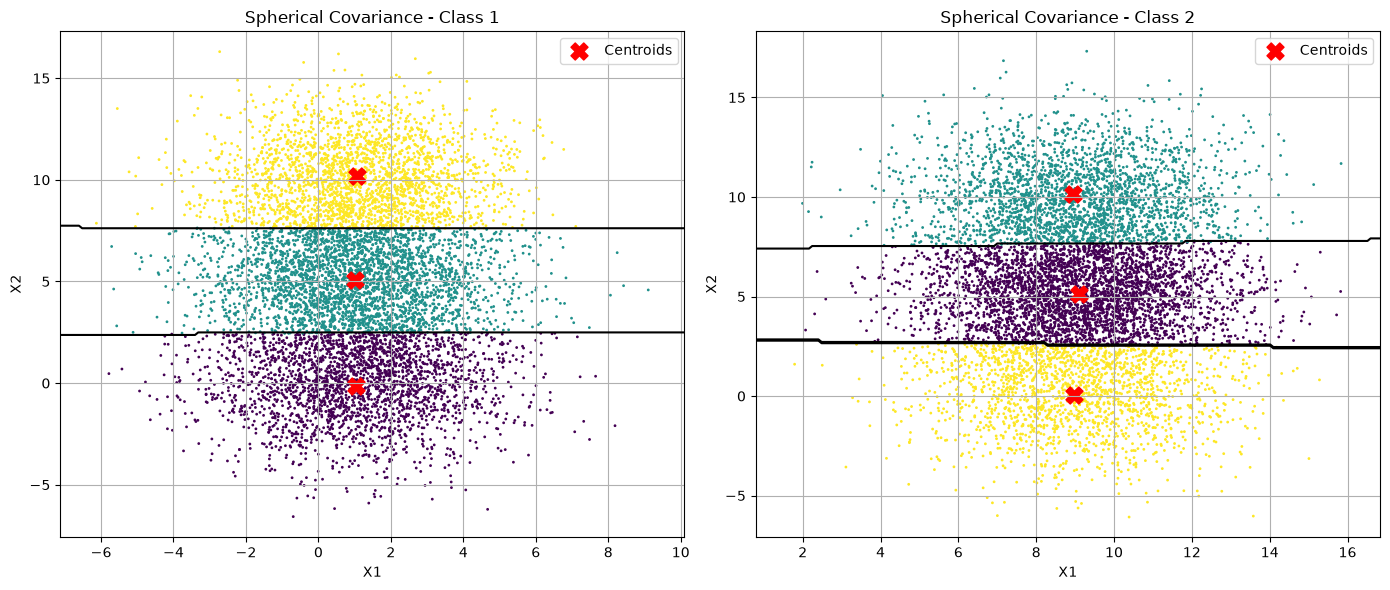

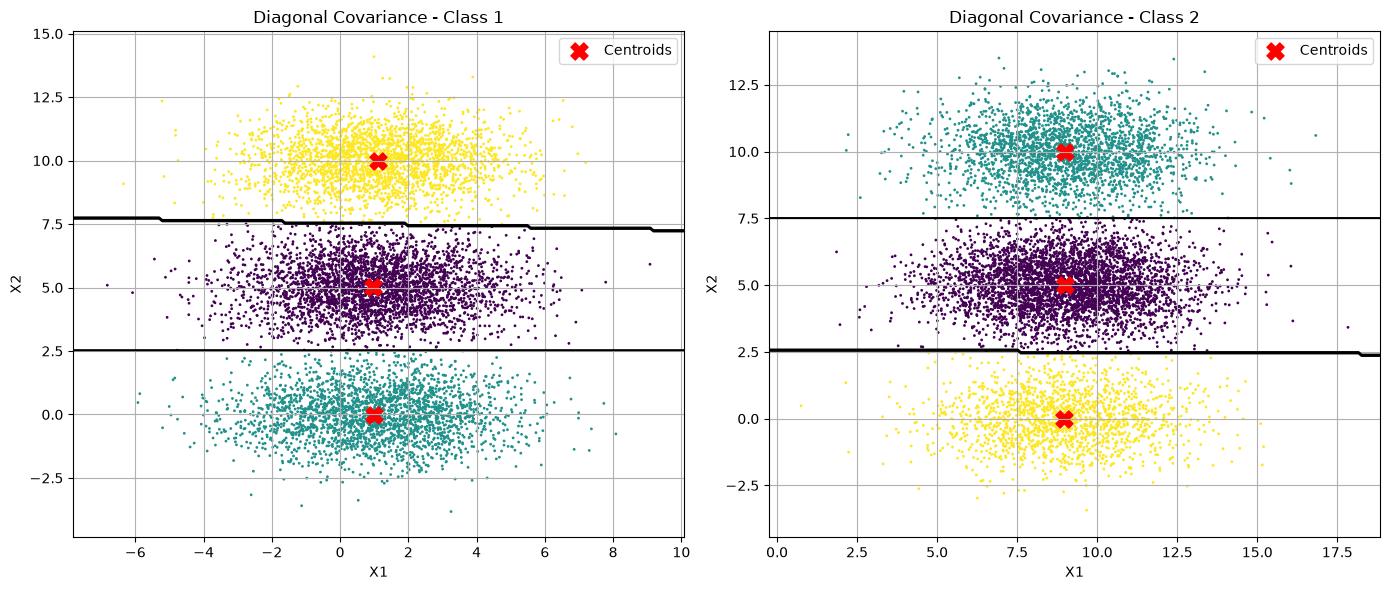

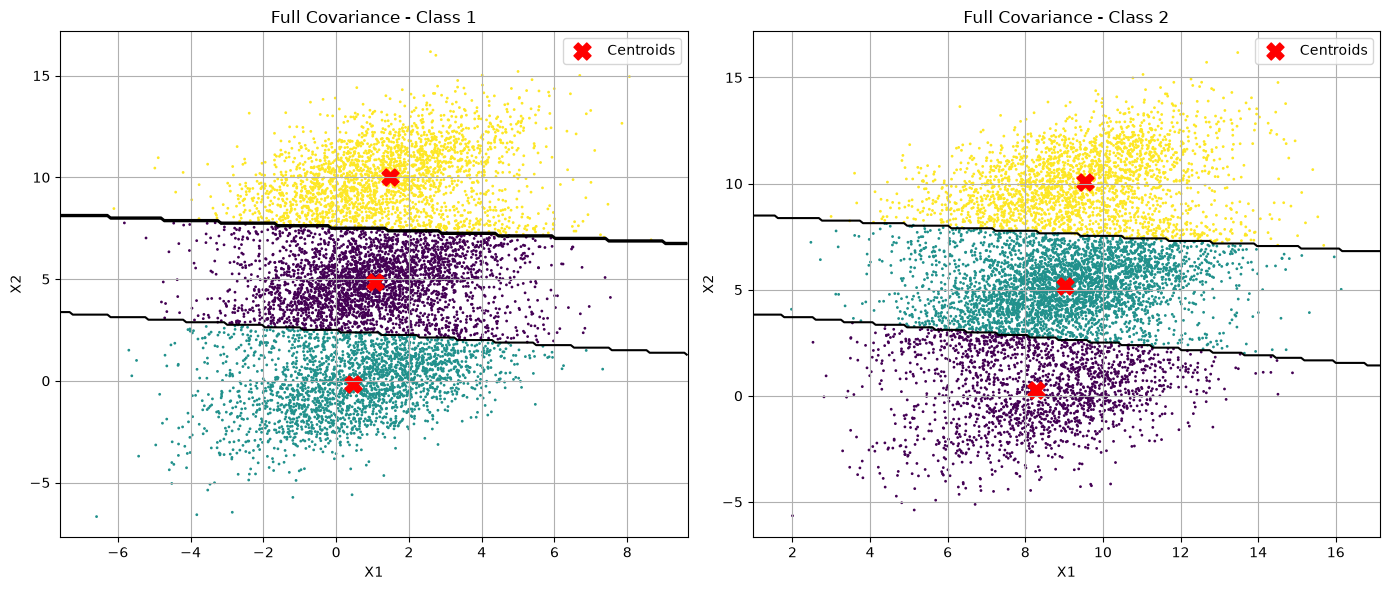

In [23]:
for name in datasets:
    fig,axes=plt.subplots(1,2,figsize=(14,6))

    for i,ax in enumerate(axes,start=1):
        X=datasets[name]["train"+str(i)]
        centroids=datasets[name]["centroids"+str(i)]
        labels=datasets[name]["labels"+str(i)]

        ax.scatter(X[:,0],X[:,1],c=labels,cmap="viridis",s=1)
        ax.scatter(centroids[:,0],centroids[:,1],c="red",marker="X",s=150,label="Centroids")

        x=np.linspace(X[:,0].min()-1,X[:,0].max()+1,200)
        y=np.linspace(X[:,1].min()-1,X[:,1].max()+1,200)
        xx,yy=np.meshgrid(x,y)
        grid=np.c_[xx.ravel(),yy.ravel()]

        distances=np.zeros((len(grid),len(centroids)))

        for j in range(len(centroids)):
            distances[:,j]=np.sum((grid-centroids[j])**2,axis=1)

        regions=np.argmin(distances,axis=1).reshape(xx.shape)
        ax.contour(xx,yy,regions,levels=[0.5,1.5],colors="black")

        ax.set_title(name+" - Class "+str(i))
        ax.set_xlabel("X1")
        ax.set_ylabel("X2")
        ax.legend()
        ax.grid(True)

    plt.tight_layout()
    plt.show()

In [24]:

def classify(X, centroids1, centroids2):
    predictions = []

    for x in X:
        # Distortion from Class 1 centroids
        d1 = np.sum((centroids1 - x) ** 2, axis=1)
        min_d1 = np.min(d1)

        # Distortion from Class 2 centroids
        d2 = np.sum((centroids2 - x) ** 2, axis=1)
        min_d2 = np.min(d2)

        # Predict the class
        if min_d1 < min_d2:
            predictions.append(1)
        else:
            predictions.append(2)

    return np.array(predictions)


# Classification and accuracy for all covariance types
for name in datasets:
    test1 = datasets[name]["test1"]
    test2 = datasets[name]["test2"]

    centroids1 = datasets[name]["centroids1"]
    centroids2 = datasets[name]["centroids2"]

    # Combine testing datasets
    X_test = np.vstack((test1, test2))

    # Actual class labels
    y_test = np.array([1] * len(test1) + [2] * len(test2))

    y_pred = classify(X_test, centroids1, centroids2)

    # Calculate correct predictions and accuracy
    correct = np.sum(y_test == y_pred)
    total = len(y_test)
    accuracy = (correct / total) * 100

    # Store results
    datasets[name]["X_test"] = X_test
    
    datasets[name]["y_test"] = y_test
    datasets[name]["y_pred"] = y_pred
    datasets[name]["correct"] = correct
    datasets[name]["accuracy"] = accuracy

    # Result
    print(f"\n  Covariance : {name}")
    print("Total Test Points:", total)
    print("Correct Predictions:", correct)
    print("Accuracy:", round(accuracy, 2), "%")


  Covariance : Spherical Covariance
Total Test Points: 4000
Correct Predictions: 3911
Accuracy: 97.78 %

  Covariance : Diagonal Covariance
Total Test Points: 4000
Correct Predictions: 3912
Accuracy: 97.8 %

  Covariance : Full Covariance
Total Test Points: 4000
Correct Predictions: 3918
Accuracy: 97.95 %


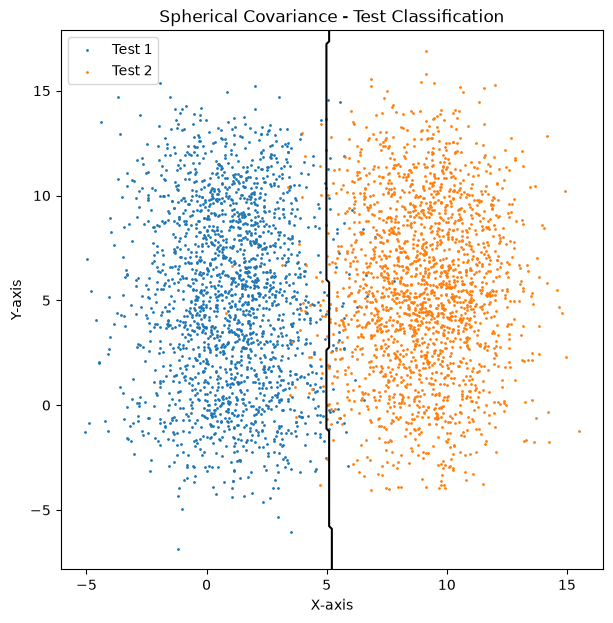

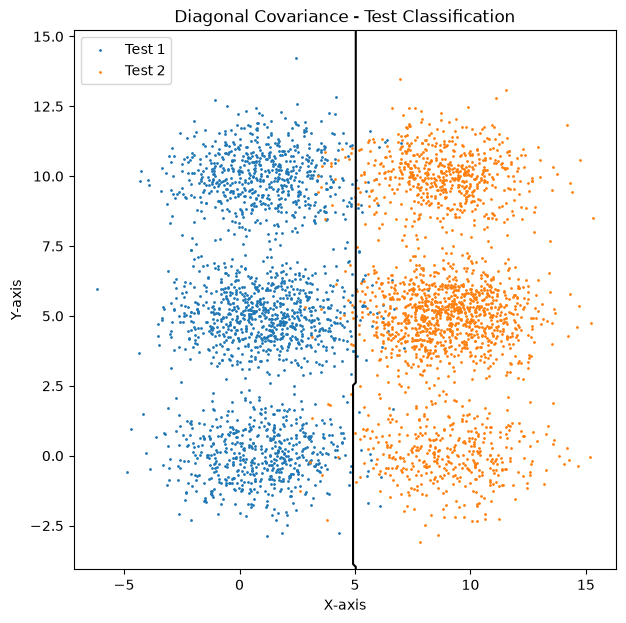

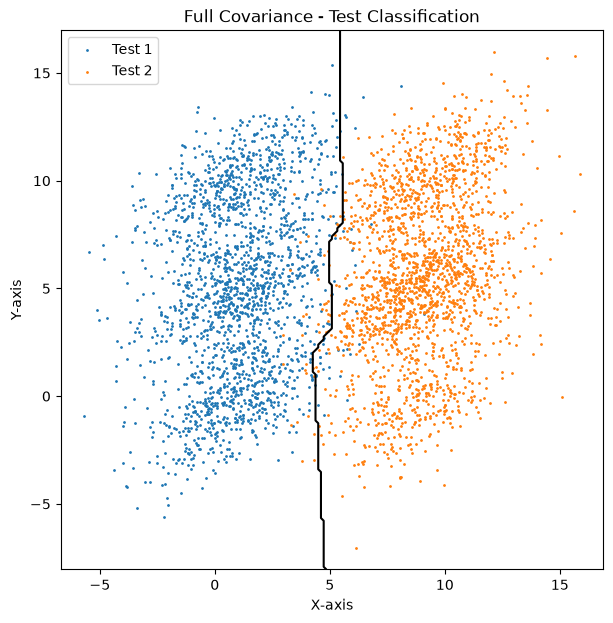

In [25]:
for name in datasets:
    test1 = datasets[name]["test1"]
    test2 = datasets[name]["test2"]
    centroids1 = datasets[name]["centroids1"]
    centroids2 = datasets[name]["centroids2"]

    X = np.vstack((test1, test2))
    x = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200)
    y = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200)
    xx, yy = np.meshgrid(x, y)
    grid = np.c_[xx.ravel(), yy.ravel()]

    decision = classify(grid, centroids1, centroids2)
    decision = decision.reshape(xx.shape)

    plt.figure(figsize=(7, 7), facecolor="white")
    ax = plt.gca()
    ax.set_facecolor("white")

    plt.contourf(
        xx, yy, decision,
        levels=[0.5, 1.5, 2.5],
        colors=["white", "white"]
    )

    plt.contour(
        xx, yy, decision,
        levels=[1.5],
        colors="black",
        linewidths=1.5
    )

    plt.scatter(np.array(test1)[:, 0], np.array(test1)[:, 1],
                s=1, label="Test 1")
    
    plt.scatter(np.array(test2)[:, 0], np.array(test2)[:, 1],
                s=1, label="Test 2")
    
    plt.title(f"{name} - Test Classification")
    plt.xlabel("X-axis")
    plt.ylabel("Y-axis")
    
    ax.legend(loc="upper left")

    
    plt.grid(False)
    plt.show()


Spherical Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

Confusion Matrix:
[[1952   48]
 [  40 1960]]
Accuracy: 97.8 %


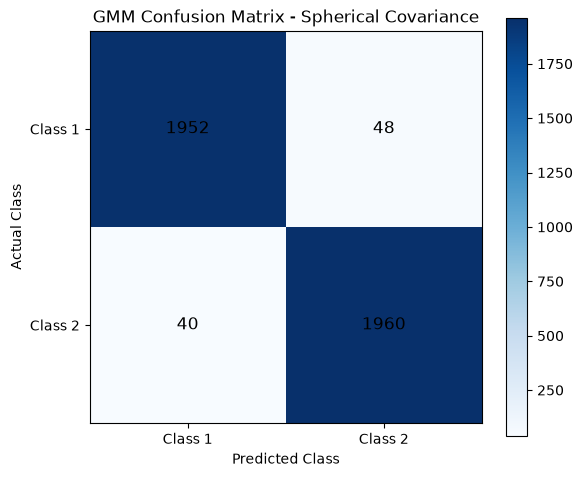


Diagonal Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

Confusion Matrix:
[[1976   24]
 [  45 1955]]
Accuracy: 98.28 %


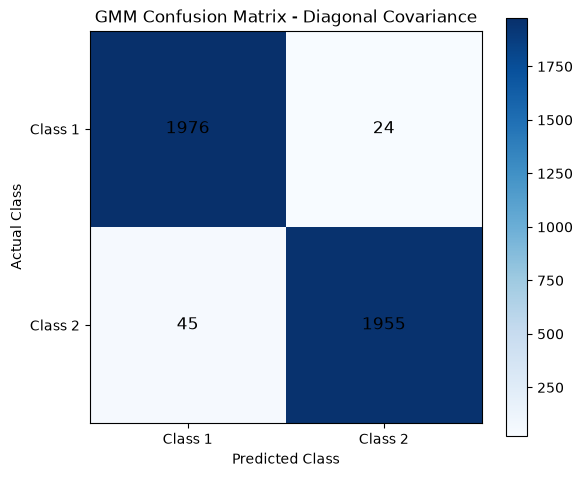


Full Covariance
Class 1 Training: (8000, 2)
Class 1 Testing: (2000, 2)
Class 2 Training: (8000, 2)
Class 2 Testing: (2000, 2)

Confusion Matrix:
[[1962   38]
 [  31 1969]]
Accuracy: 98.28 %


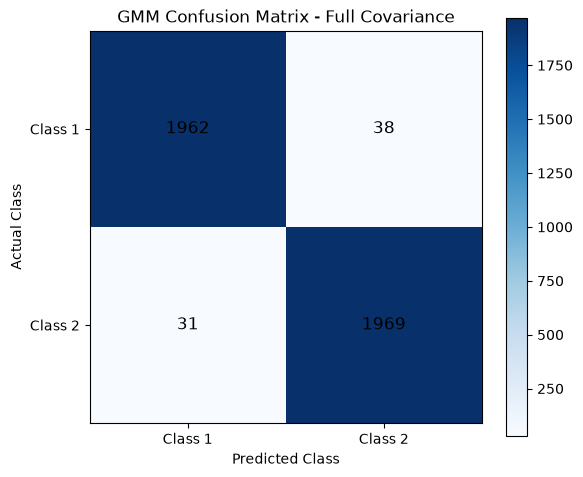

In [26]:
def generate_data(means,weights,C,n):
    data=[]
    A=covariance_transform(C)

    for _ in range(n):
        k=select_component(weights)
        z=box_muller()
        x=np.array(means[k])+A@z
        data.append(x)

    return np.array(data)


def split_data(X):
    X=np.asarray(X).copy()

    n_train=int(0.8*len(X))

    for i in range(len(X)-1,0,-1):
        j=int(random_number()*(i+1))
        X[i],X[j]=X[j].copy(),X[i].copy()

    return X[:n_train],X[n_train:]

# Train GMM using EM
def gmm_train(X,K=3,iterations=100):
    n,d=X.shape
    means=X[np.linspace(0,n-1,K,dtype=int)].copy()
    covs=np.array([np.cov(X.T)+np.eye(d)*1e-5 for _ in range(K)])
    weights=np.ones(K)/K

    for _ in range(iterations):
        log_prob=np.zeros((n,K))

        for k in range(K):
            diff=X-means[k]
            inv=np.linalg.inv(covs[k])
            _,ld=np.linalg.slogdet(covs[k])
            log_prob[:,k]=np.log(weights[k])-0.5*(
                d*np.log(2*np.pi)+ld+
                np.sum((diff@inv)*diff,axis=1)
            )

        log_prob-=np.max(log_prob,axis=1,keepdims=True)
        prob=np.exp(log_prob)
        prob/=np.sum(prob,axis=1,keepdims=True)

        nk=np.sum(prob,axis=0)+1e-10
        weights=nk/n
        means=(prob.T@X)/nk[:,None]

        for k in range(K):
            diff=X-means[k]
            covs[k]=(diff.T*prob[:,k])@diff/nk[k]
            covs[k]+=np.eye(d)*1e-5

    return means,covs,weights

# Calculate GMM log-likelihood
def gmm_score(X,model):
    means,covs,weights=model
    n,d=X.shape
    log_prob=np.zeros((n,len(weights)))

    for k in range(len(weights)):
        diff=X-means[k]
        inv=np.linalg.inv(covs[k])
        _,ld=np.linalg.slogdet(covs[k])
        log_prob[:,k]=np.log(weights[k])-0.5*(
            d*np.log(2*np.pi)+ld+
            np.sum((diff@inv)*diff,axis=1)
        )

    maximum=np.max(log_prob,axis=1)
    return maximum+np.log(
        np.sum(np.exp(log_prob-maximum[:,None]),axis=1)
    )

# Generate and classify data for all covariance types
covariances=[
    ("Spherical Covariance",C_spherical),
    ("Diagonal Covariance",C_diagonal),
    ("Full Covariance",C_full)
]

for name,C in covariances:
    X1=generate_data(mu1,pi1,C,n)
    X2=generate_data(mu2,pi2,C,n)

    train1,test1=split_data(X1)
    train2,test2=split_data(X2)

    # Train separate GMM models for each class
    model1=gmm_train(train1,K)
    model2=gmm_train(train2,K)

    # Combine test data
    X_test=np.vstack((test1,test2))
    actual=np.array([1]*len(test1)+[2]*len(test2))

    # Classify test samples
    score1=gmm_score(X_test,model1)
    score2=gmm_score(X_test,model2)
    predicted=np.where(score1>score2,1,2)

    # Generate confusion matrix
    cm=np.array([
        [np.sum((actual==1)&(predicted==1)),
         np.sum((actual==1)&(predicted==2))],
        [np.sum((actual==2)&(predicted==1)),
         np.sum((actual==2)&(predicted==2))]
    ])

    accuracy=np.trace(cm)/np.sum(cm)*100

    print("\n"+name)
    print("Class 1 Training:",train1.shape)
    print("Class 1 Testing:",test1.shape)
    print("Class 2 Training:",train2.shape)
    print("Class 2 Testing:",test2.shape)
    print("\nConfusion Matrix:")
    print(cm)
    print("Accuracy:",round(accuracy,2),"%")

    # Plot confusion matrix
    plt.figure(figsize=(6,5))
    plt.imshow(cm,cmap="Blues")
    plt.title("GMM Confusion Matrix - "+name)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks([0,1],["Class 1","Class 2"])
    plt.yticks([0,1],["Class 1","Class 2"])

    for i in range(2):
        for j in range(2):
            plt.text(j,i,str(cm[i,j]),ha="center",va="center",fontsize=12)

    plt.colorbar()
    plt.tight_layout()
    plt.show()

In [30]:

# GMM classification boundary
def plot_gmm_boundary(X1,X2,model1,model2,name):
    x_min=min(X1[:,0].min(),X2[:,0].min())-2
    x_max=max(X1[:,0].max(),X2[:,0].max())+2
    y_min=min(X1[:,1].min(),X2[:,1].min())-2
    y_max=max(X1[:,1].max(),X2[:,1].max())+2

    # Create grid points
    xx,yy=np.meshgrid(
        np.linspace(x_min,x_max,100),
        np.linspace(y_min,y_max,100)
    )
    grid=np.column_stack((xx.ravel(),yy.ravel()))

    # Calculate GMM scores
    score1=gmm_score(grid,model1)
    score2=gmm_score(grid,model2)
    boundary=(score2>score1).astype(int).reshape(xx.shape)

    # Plot classification regions
    plt.figure(figsize=(8,6))
    plt.contourf(
        xx,yy,boundary,
        levels=[-0.5,0.5,1.5],
        alpha=0.3,cmap="coolwarm"
    )

    # Draw decision boundary only when both regions exist
    if boundary.min()!=boundary.max():
        plt.contour(
            xx,yy,boundary,
            levels=[0.5],colors="black",linewidths=2
        )

    # Plot both classes
    plt.scatter(X1[:,0],X1[:,1],s=1,alpha=0.35,label="Class 1")
    plt.scatter(X2[:,0],X2[:,1],s=1,alpha=0.35,label="Class 2")

    plt.title("GMM Classification Boundary - "+name)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.tight_layout()

    # Save without replacing confusion matrix images
    filename="GMM_Images/"+name.lower().replace(" ","_")+"_classification_boundary.png"
    plt.savefig(filename,dpi=300,bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:",filename)


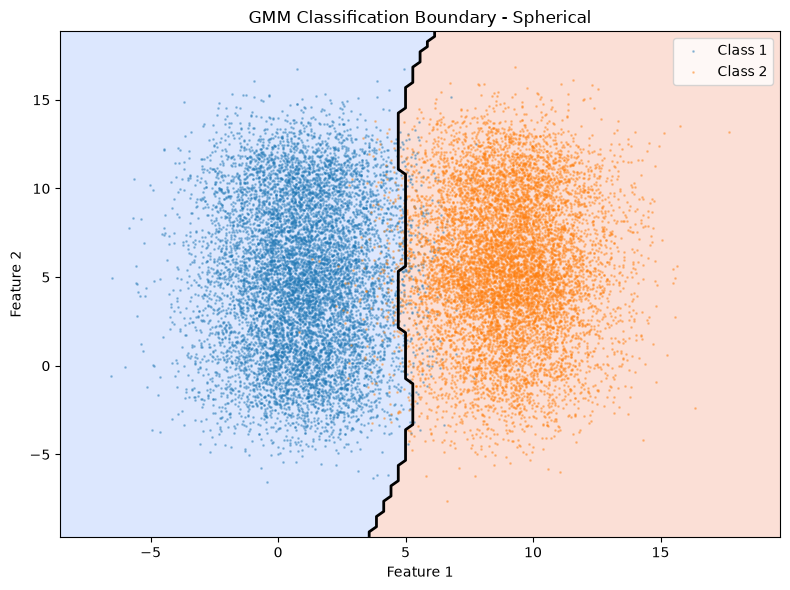

Saved: GMM_Images/spherical_classification_boundary.png


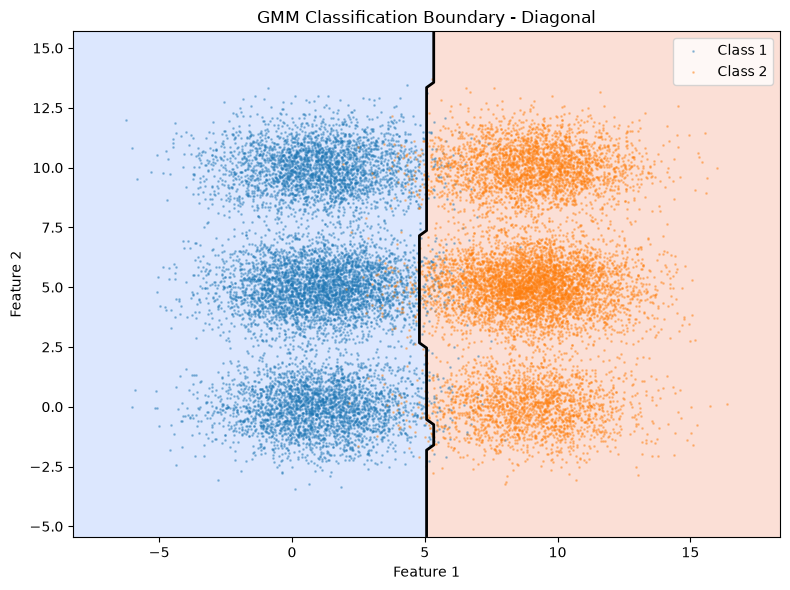

Saved: GMM_Images/diagonal_classification_boundary.png


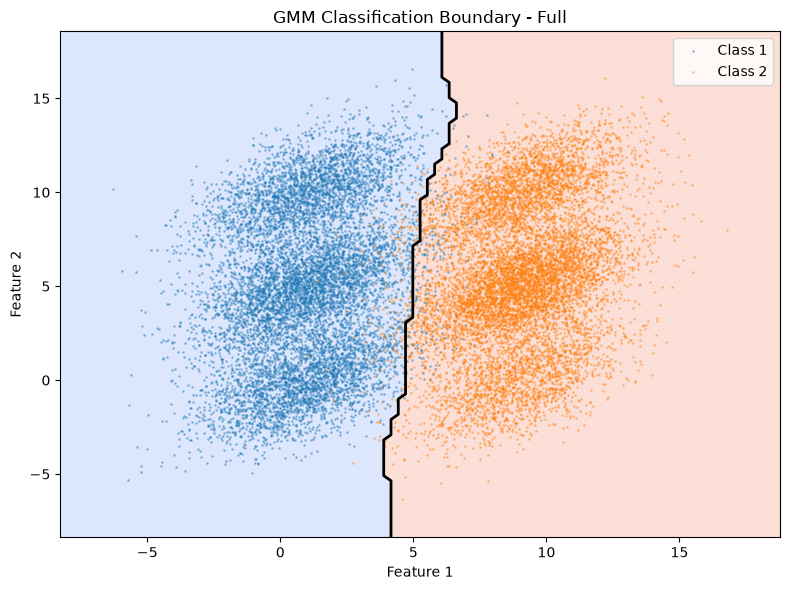

Saved: GMM_Images/full_classification_boundary.png


In [31]:
covariances=[
    ("Spherical",C_spherical,"spherical"),
    ("Diagonal",C_diagonal,"diagonal"),
    ("Full",C_full,"full")
]# Generate data, train models, and plot boundaries
for name,C,cov_type in covariances:
    X1=generate_data(mu1,pi1,C,n)
    X2=generate_data(mu2,pi2,C,n)

    train1,test1=split_data(X1)
    train2,test2=split_data(X2)

    model1=gmm_train(train1,K,100)
    model2=gmm_train(train2,K,100)

    plot_gmm_boundary(X1,X2,model1,model2,name)